# <center>👁️ Лекция 8. Компьютерное зрение и обработка речи</center>
## <center>计算机视觉与语音处理</center>

### <center>Прикладные технологии искусственного интеллекта</center>
#### <center>Модуль 4 — Основные сценарии применения ИИ · 2 академических часа (90 минут)</center>

<div style='background-color: #E8F5E9; padding: 15px; border-left: 5px solid #2E7D32; margin: 20px 0;'>
<b>🎯 Цели лекции:</b><br>
1. различать три задачи зрения — классификацию, обнаружение, сегментацию — и называть по примеру каждой;<br>2. выполнять базовые операции OpenCV: яркость, контраст, порог, размытие, грани, цветовые пространства;<br>3. объяснять идею современных детекторов (сетка ячеек, один проход) и конвейер распознавания лиц;<br>4. описывать речевой конвейер: волна → спектрограмма → модель → текст (и обратно, TTS);<br>5. читать спектрограмму и связывать её со слухом (тон, громкость, форманты);<br>6. знать готовые инструменты (OpenCV, MediaPipe, Hugging Face) и границы их применимости.
</div>

<div style='background-color: #FFF3E0; padding: 12px; border-left: 5px solid #FB8C00; margin: 20px 0;'>
<b>⏱️ План работы (90 минут):</b><br>
• Три задачи зрения + почему зрение сложно <i>(15 мин)</i><br>• OpenCV: пиксельные операции и цвет <i>(20 мин)</i><br>• Обнаружение объектов и лица <i>(20 мин)</i><br>• Речь: волна, спектрограмма, ASR/TTS <i>(20 мин)</i><br>• Готовые модели и где применяется <i>(10 мин)</i><br>• Мини-тест и итоги <i>(5 мин)</i>
</div>

<div style='background-color: #E3F2FD; padding: 12px; border-left: 5px solid #1976D2; margin: 20px 0;'>
<b>📦 Что понадобится:</b> OpenCV, MediaPipe, Hugging Face, matplotlib, numpy.
</div>

<div style='background-color: #FCE4EC; padding: 12px; border-left: 5px solid #C2185B; margin: 20px 0;'>
<b>💡 Как работать с ноутбуком.</b> Теория читается сверху вниз; все рисунки уже внедрены в файл — внешние контейнеры и сетка не нужны. Демонстрационные ячейки с кодом можно запускать по порядку.
</div>


In [ ]:
# Настройка ноутбука: графики внутри документа, кириллица и иероглифы
%matplotlib inline
import numpy as np
import matplotlib.font_manager as fm
import os
for fp in ['/usr/share/fonts/truetype/chinese/NotoSansSC-Regular.ttf']:
    if os.path.exists(fp):
        fm.fontManager.addfont(fp)
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Noto Sans SC', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
print('Настройка завершена. Запускайте ячейки по порядку — сверху вниз.')

import matplotlib.pyplot as plt
import platform

# Автоматический выбор шрифта в зависимости от ОС
system = platform.system()
if system == 'Windows':
    # На Windows используем SimHei или Microsoft YaHei
    plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
elif system == 'Darwin':  # macOS
    plt.rcParams['font.sans-serif'] = ['Arial Unicode MS', 'PingFang SC', 'Heiti TC']
else:  # Linux
    plt.rcParams['font.sans-serif'] = ['WenQuanYi Micro Hei', 'Noto Sans CJK SC', 'DejaVu Sans']

# Отключаем минус (иначе отрицательные числа отображаются как квадратики)
plt.rcParams['axes.unicode_minus'] = False

print("✅ Шрифты matplotlib настроены для поддержки CJK (китайский/японский/корейский)")

Настройка завершена. Запускайте ячейки по порядку — сверху вниз.
✅ Шрифты matplotlib настроены для поддержки CJK (китайский/японский/корейский)


## 1. Зрение: три задачи и одна трудность

### 1.1. Классификация, обнаружение, сегментация


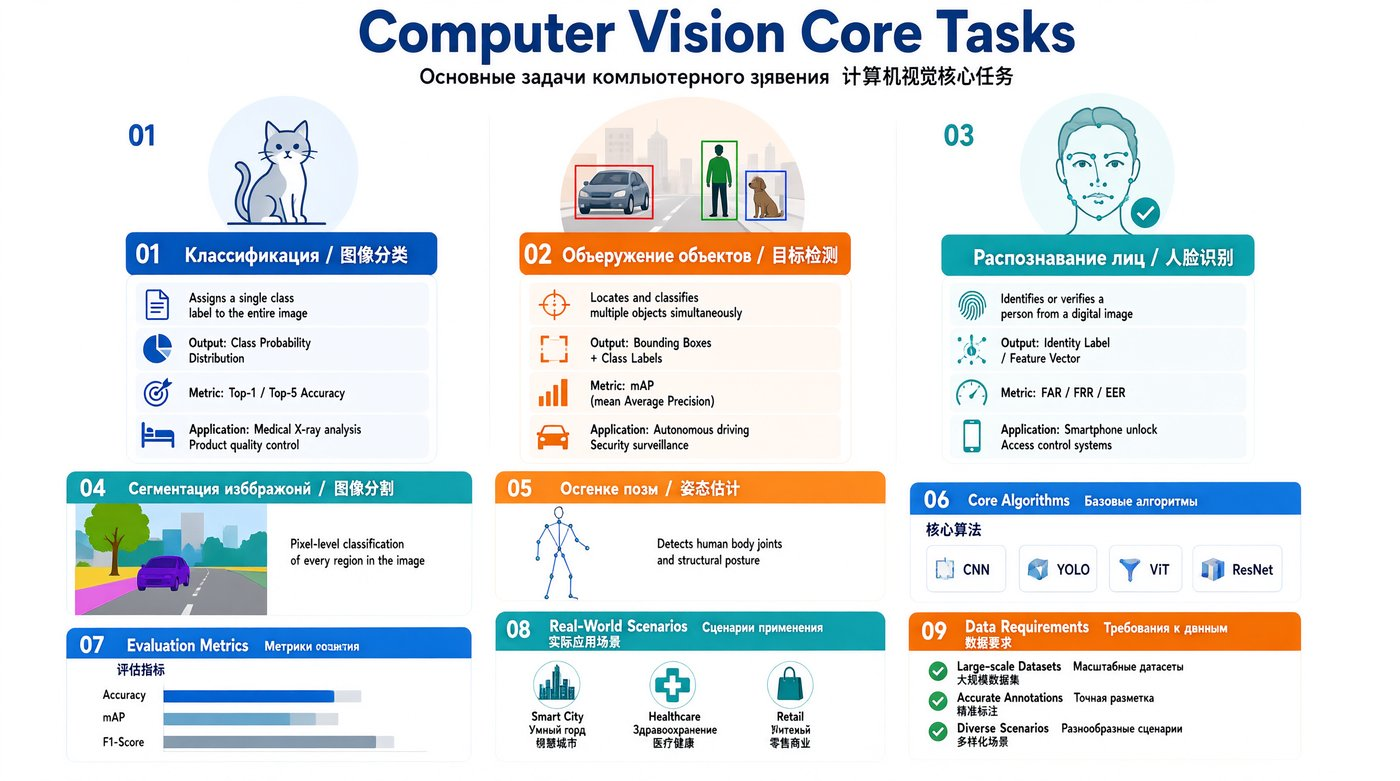
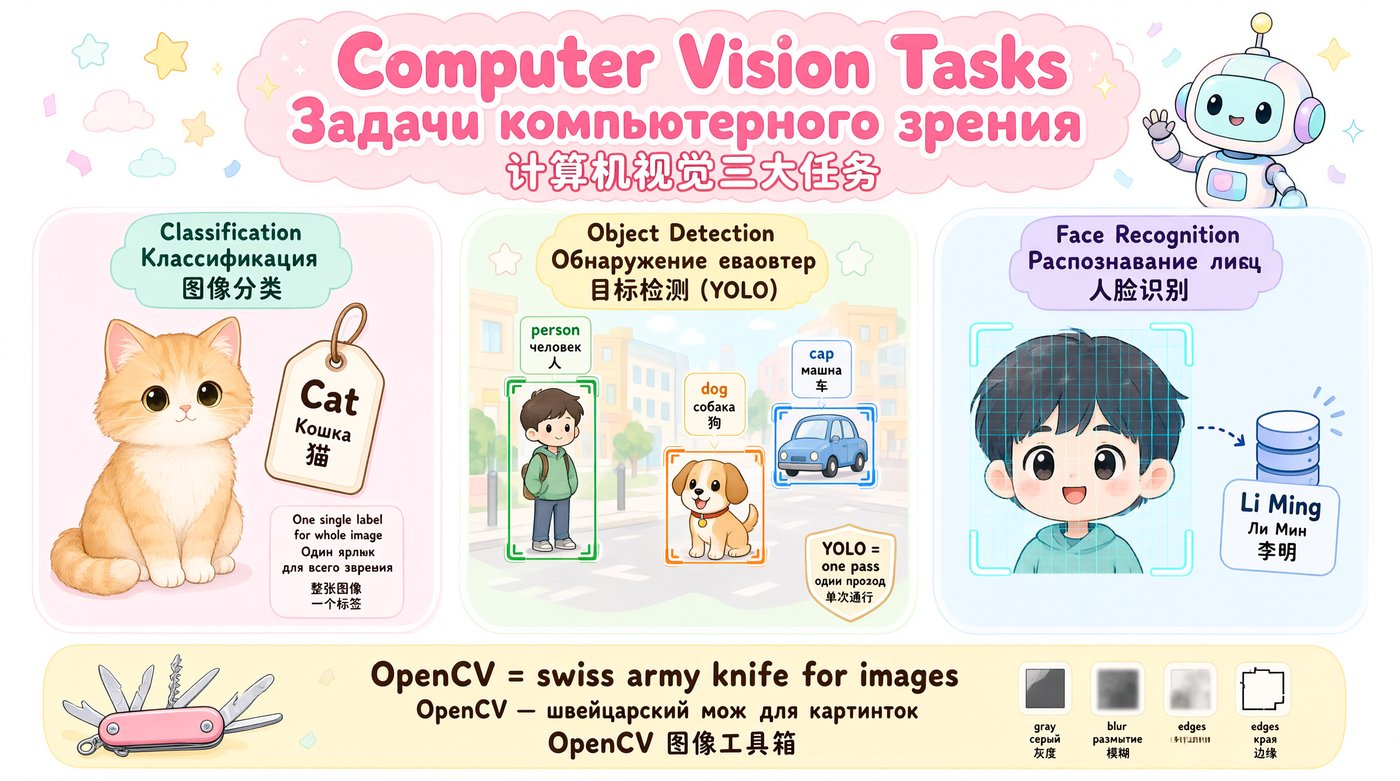

## 1. Компьютерное зрение (计算机视觉, Computer Vision) (0–25 мин)

Компьютерное зрение — это область ИИ, где модель «понимает» изображения. Три классические задачи:

### 🖼️ 1. Классификация изображений («Что на фото?», 图像分类)
Модель выдаёт **один ярлык (метку)** на всю картинку.  
*Пример:* на фото → **«кошка»** или **«собака»** (без указания, где именно она находится).

### 📦 2. Обнаружение объектов («Где что находится?», 目标检测)
Модель рисует **ограничительные рамки (bounding boxes)** вокруг нескольких предметов и подписывает их.  
*Пример:* на фото найдено 3 объекта: «человек» (рамка 1), «собака» (рамка 2), «машина» (рамка 3).

**🚀 Алгоритм YOLO (You Only Look Once):** Знаменитый алгоритм, который обнаруживает все объекты **за один проход** нейросети. Очень быстрый, поэтому используется в камерах наблюдения, автопилотах и спортивных трансляциях в реальном времени.

### 👤 3. Распознавание лиц (人脸识别)
Специальный случай: модель ищет ключевые точки (глаза, нос, контур лица), превращает их в математический вектор и сравнивает с базой данных.  
*Примеры:* разблокировка телефона по лицу, оплата лицом в Alipay и WeChat Pay, проход в офис.

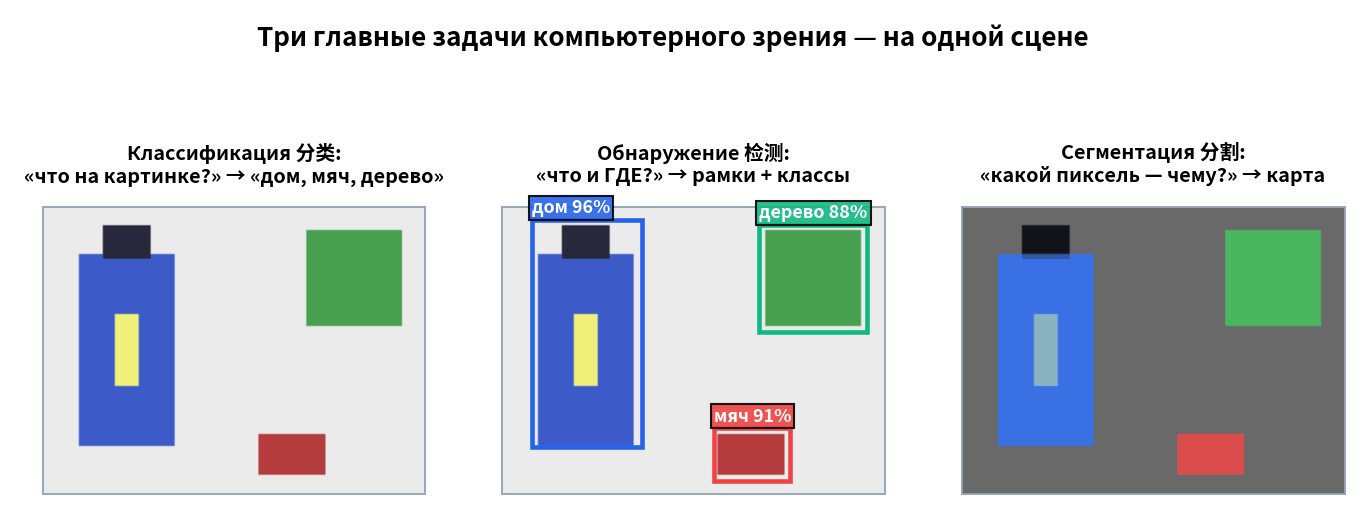

| Задача | Вопрос | Выход модели | Пример применения |
|---|---|---|---|
| Классификация | что на картинке? | метка | контроль брака «норма/дефект» |
| Обнаружение (детекция) | что и где? | рамки + классы + уверенность | беспилотник, видеонаблюдение |
| Сегментация | какой пиксель кому? | маска-раскраска | медицинские снимки, редакторы |

Сложность растёт слева направо, и архитектуры тоже: CNN из лекции 6 закрывает классификацию; для рамок и масок нужны специальные «головы» на том же.backbone.

### 1.2. Почему зрение сложно


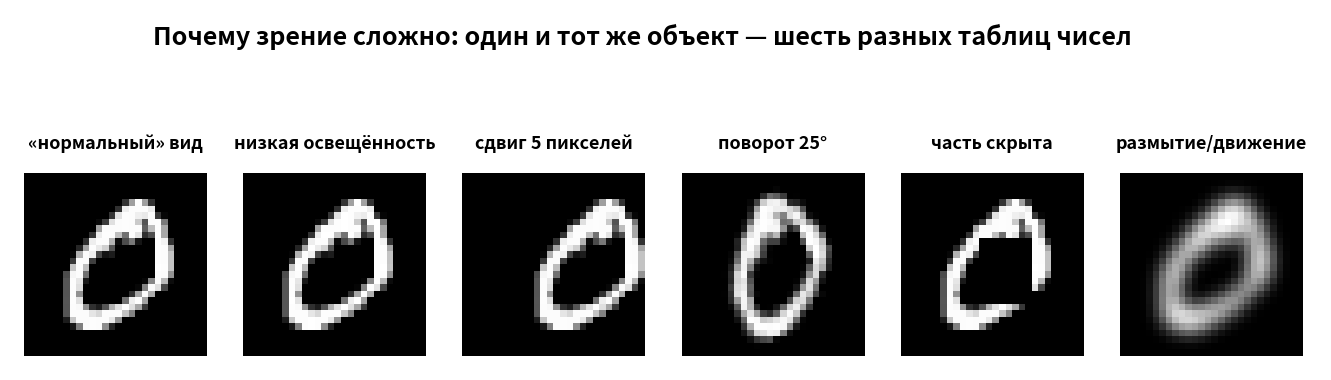

Человек узнаёт «семёрку» при любом освещении и повороте. Для модели это **шесть разных таблиц чисел**, не похожих друг на друга. Отсюда два практических вывода: (1) в обучающую выборку обязаны попасть все «вариации» (или аугментация их синтезирует); (2) качество в бою ≠ качеству в лаборатории — тестируйте на реальных кадрах с ваших камер.


## 2. OpenCV: пиксельная гигиена

**OpenCV** (开源计算机视觉库) — библиотека с 25-летней историей: 2500+ операций от «изменить яркость» до стереозрения. Практика 7 построена на ней; здесь — витрина базовых операций:

### 🔧 Библиотека OpenCV
**OpenCV (Open Computer Vision)** — самая популярная библиотека для работы с картинками. Это как «швейцарский нож» для программиста CV.  
Базовые операции, которые делают почти в каждом CV-проекте:
- **Grayscale (灰度化):** Перевод в чёрно-белый (1 канал вместо 3) — меньше данных, быстрее обработка.
- **Размытие (Blur):** Убирает шум и мелкие детали.
- **Поиск границ (Edge Detection, 边缘检测):** Находит контуры объектов (алгоритм Кэнни).


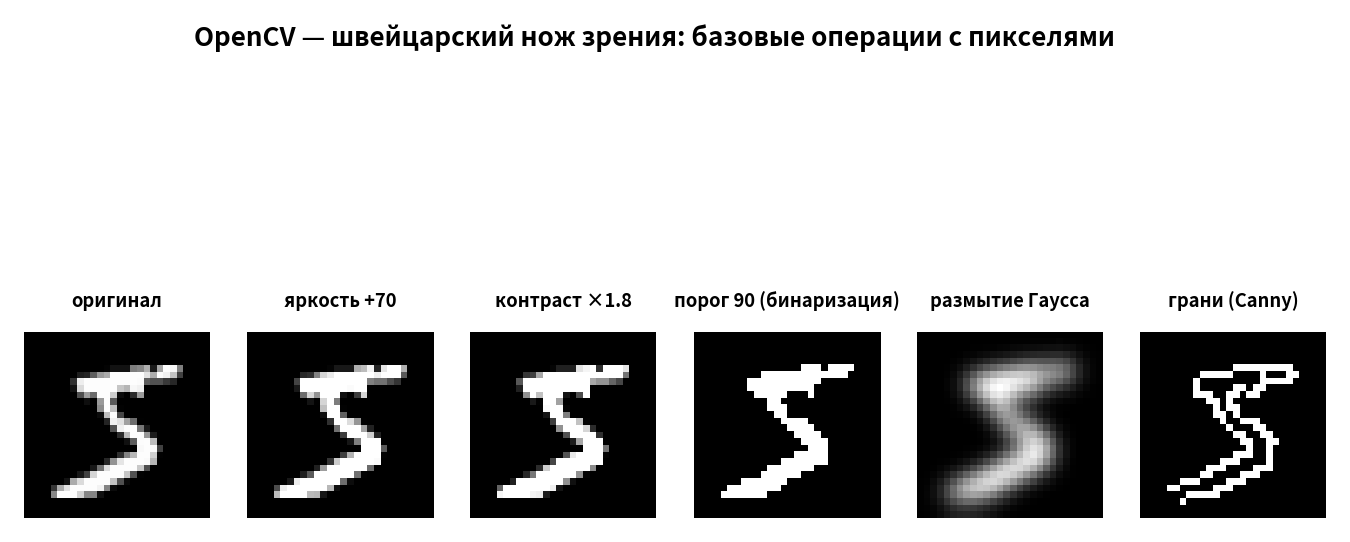

Пороговая бинаризация — рабочая лошадка простых инспекций («деталь темнее нормы → брак»); размытие — шумодав перед детекцией граней; Canny — классика выделения контуров.

**Цветовые пространства** — вторая базовая идея:


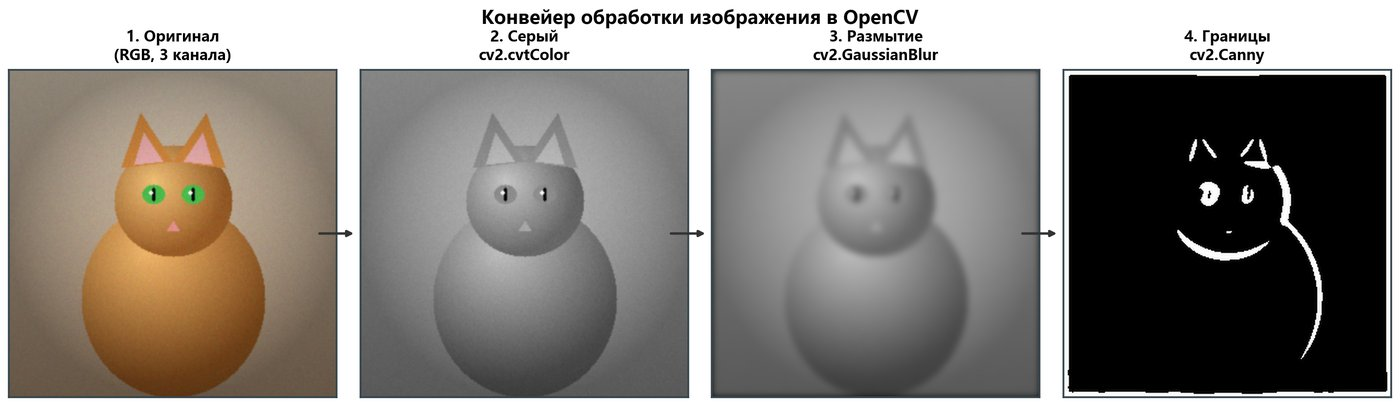

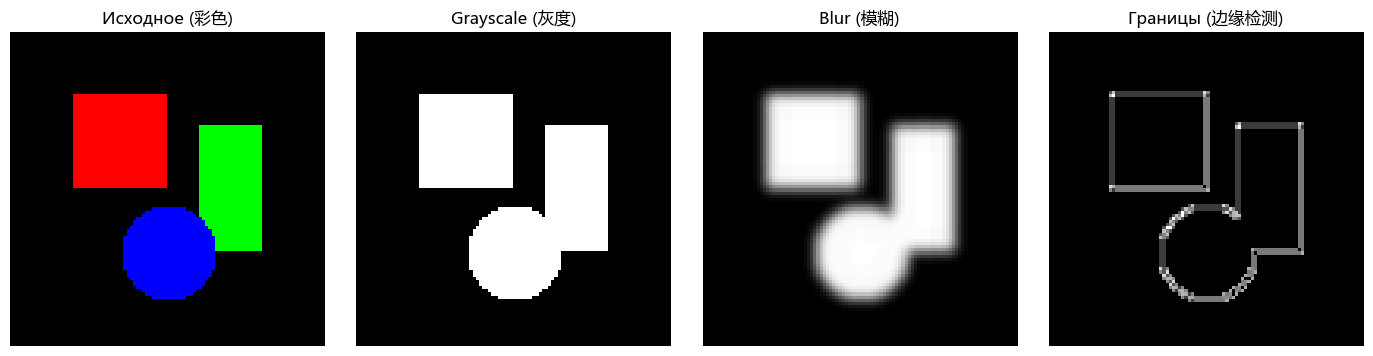

🔍 OpenCV делает всё это одной-двумя строчками кода:
   cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
   cv2.GaussianBlur(img, (5, 5), 0)
   cv2.Canny(img, 100, 200)


In [ ]:
# Демонстрация базовой обработки изображения (имитация OpenCV через numpy/matplotlib)
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage

# Создадим синтетическое изображение: геометрические фигуры на фоне
img = np.zeros((100, 100, 3), dtype=np.uint8)
img[20:50, 20:50] = [255, 0, 0]      # Красный квадрат
img[30:70, 60:80] = [0, 255, 0]      # Зелёный прямоугольник
# Нарисуем круг вручную
Y, X = np.ogrid[:100, :100]
mask = (X - 50)**2 + (Y - 70)**2 < 15**2
img[mask] = [0, 0, 255]              # Синий круг

# 1. Перевод в оттенки серого (grayscale)
gray = np.mean(img, axis=2).astype(np.uint8)

# 2. Размытие (Gaussian blur)
blurred = ndimage.gaussian_filter(gray, sigma=2)

# 3. Обнаружение границ (оператор Собеля — упрощённая версия Кэнни)
sx = ndimage.sobel(gray, axis=0)
sy = ndimage.sobel(gray, axis=1)
edges = np.hypot(sx, sy)
edges = (edges / edges.max() * 255).astype(np.uint8)

# Визуализация всех этапов
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
axes[0].imshow(img)
axes[0].set_title("Исходное (彩色)")
axes[0].axis('off')

axes[1].imshow(gray, cmap='gray')
axes[1].set_title("Grayscale (灰度)")
axes[1].axis('off')

axes[2].imshow(blurred, cmap='gray')
axes[2].set_title("Blur (模糊)")
axes[2].axis('off')

axes[3].imshow(edges, cmap='gray')
axes[3].set_title("Границы (边缘检测)")
axes[3].axis('off')

plt.tight_layout()
plt.show()

print("🔍 OpenCV делает всё это одной-двумя строчками кода:")
print("   cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)")
print("   cv2.GaussianBlur(img, (5, 5), 0)")
print("   cv2.Canny(img, 100, 200)")

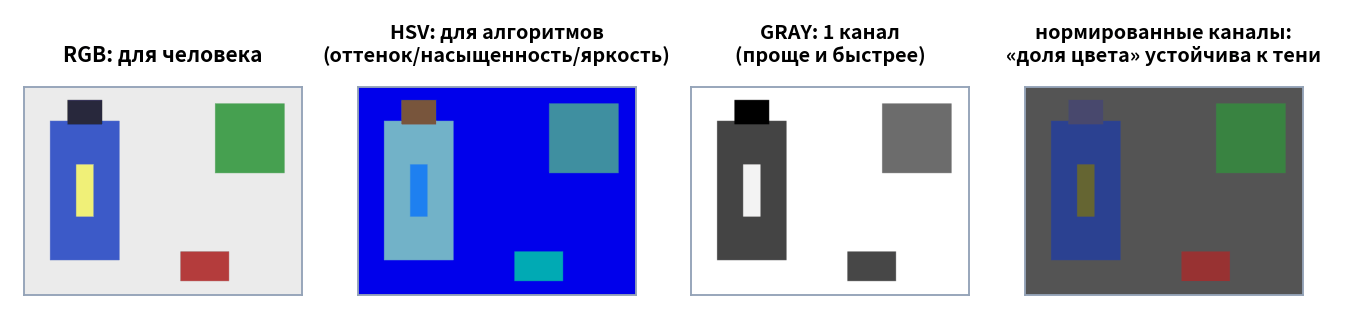

RGB хранит «сколько красного/зелёного/синего» — удобно человеку, но чувствительно к тени. **HSV** разделяет оттенок, насыщенность и яркость: правило «только что-то красное» в HSV устойчиво к освещению, в RGB — нет. Отдельная уловка — нормировка каналов (правая панель): «доля цвета» почти не меняется в тени.


In [ ]:
# Мини-инспекция: брак по яркости (порог + доля тёмных пикселей)
import cv2

rng8 = np.random.default_rng(8)   # синтетика вместо файлов (в практике — реальные снимки)
detail_ok   = np.full((28, 28), 200, np.uint8)
detail_bad  = rng8.integers(20, 90, (28, 28)).astype(np.uint8)   # тёмная деталь

for name, img in [("годная деталь", detail_ok), ("брак (тёмная)", detail_bad)]:
    _, binary = cv2.threshold(img, 100, 255, cv2.THRESH_BINARY_INV)
    defect_share = binary.mean() / 255
    verdict = "БРАК" if defect_share > 0.4 else "норма"
    print(f"{name:14s} доля тёмных пикселей: {defect_share:.2%} → {verdict}")

годная деталь  доля тёмных пикселей: 0.00% → норма
брак (тёмная)  доля тёмных пикселей: 100.00% → БРАК


---
## 🎬 Видеоматериалы: OpenCV и звук с нуля
Практические уроки OpenCV и преобразование Фурье (спектрограмма звука) к разделам 1–2 и 4.
### 🇷🇺 РУС · русскоязычные видео (3)
| № | Видео | Источник | Длит. | Раздел лекции  | Доступность |
|---|-------|----------|-------|----------------|---|
| 1 | [Изучение Python OpenCV. Урок #2 — Работа с изображениями и видео](https://itproger.com/course/opencv/2)<br>· ориг.: *itProger, курс OpenCV* | itProger | курс | П7: чтение и преобразование изображений (cv2)  ? |
| 2 | [Py #51. Генеративно-состязательные сети (GAN)](https://rutube.ru/video/5af08b5a5772ef0b40da5f3139581e98/) | Rutube · SelfEdu | 11 мин | Л8 §6: генеративный ИИ (GAN → диффузия)  X |
| 3 | [Преобразование Фурье [3Blue1Brown]](https://rutube.ru/video/78741db2554751d0d1bd09b7837d288a/)<br>· ориг.: *But what is a Fourier transform?* | Vert Dider (VK/Rutube) | 19 мин | Л8 §4.2: спектрограмма — «фотография звука»  X |
### 🇨🇳 中文 · китайскоязычные видео (оригинал в курсиве) (9)
| № | Видео | Источник | Длит. | Раздел лекции  | Доступность |
|---|-------|----------|-------|----------------|---|
| 1 | [Введение в машинное зрение](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=69)<br>· ориг.: *01 机器视觉介绍* | Bilibili · 清华AI | 8 мин | Л8 §1: три задачи зрения  ✓ |
| 2 | [Знакомство с OpenCV](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=70)<br>· ориг.: *02 OpenCV介绍* | Bilibili · 清华AI | 7 мин | Л8 §2 / П7: что умеет библиотека  ✓ |
| 3 | [Отображение изображений](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=73)<br>· ориг.: *05 显示图像* | Bilibili · 清华AI | 17 мин | П7: imread / imshow  ✓ |
| 4 | [Операция свёртки над изображением](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=99)<br>· ориг.: *01 卷积操作* | Bilibili · 清华AI | 38 мин | Л8 §2 / Л6 §4: свёртка на картинках  ✓ |
| 5 | [Детектор границ Кэнни (Canny)](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=107)<br>· ориг.: *01 Canny边缘检测* | Bilibili · 清华AI | 28 мин | П7: практический поиск контуров  ✓ |
| 6 | [Обнаружение лиц](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=169)<br>· ориг.: *01 人脸检测* | Bilibili · 清华AI | 40 мин | Л8 §3.2: каскады Хаара и детекция лиц  ✓ |
| 7 | [Цветовые пространства RGB и BGR](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=79)<br>· ориг.: *06 RGB和BGR颜色空间* | Bilibili · 清华AI | 5 мин | Л8 §2: цвет в OpenCV  ✓ |
| 8 | [Преобразование цветовых пространств (HSV и др.)](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=81)<br>· ориг.: *02 颜色空间的转化* | Bilibili · 清华AI | 20 мин | Л8 §2: HSV для сегментации цвета  ✓ |
| 9 | [Гауссово размытие](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=101)<br>· ориг.: *03 高斯滤波* | Bilibili · 清华AI | 39 мин | Л8 §2: сглаживание изображений  ✓ |
### 🇬🇧 EN · англоязычные видео (1)
| № | Видео | Источник | Длит. | Раздел лекции  | Доступность |
|---|-------|----------|-------|----------------|---|
| 1 | [OpenCV with Python in 4 Hours (полный курс)](https://youtu.be/oXlwWbU8l2o)<br>· ориг.: *OpenCV with Python in 4 Hours — freeCodeCamp* | YouTube | курс | П7 EN: чтение изображений, фильтры, детекция лиц  X |

> 📄 Полная версия с идентичными ссылками: PDF «Видеоматериалы по 5 модулям и 10 лекциям», глава соответствующего модуля.

## 3. Обнаружение объектов и лица

### 3.1. От скользящего окна к YOLO


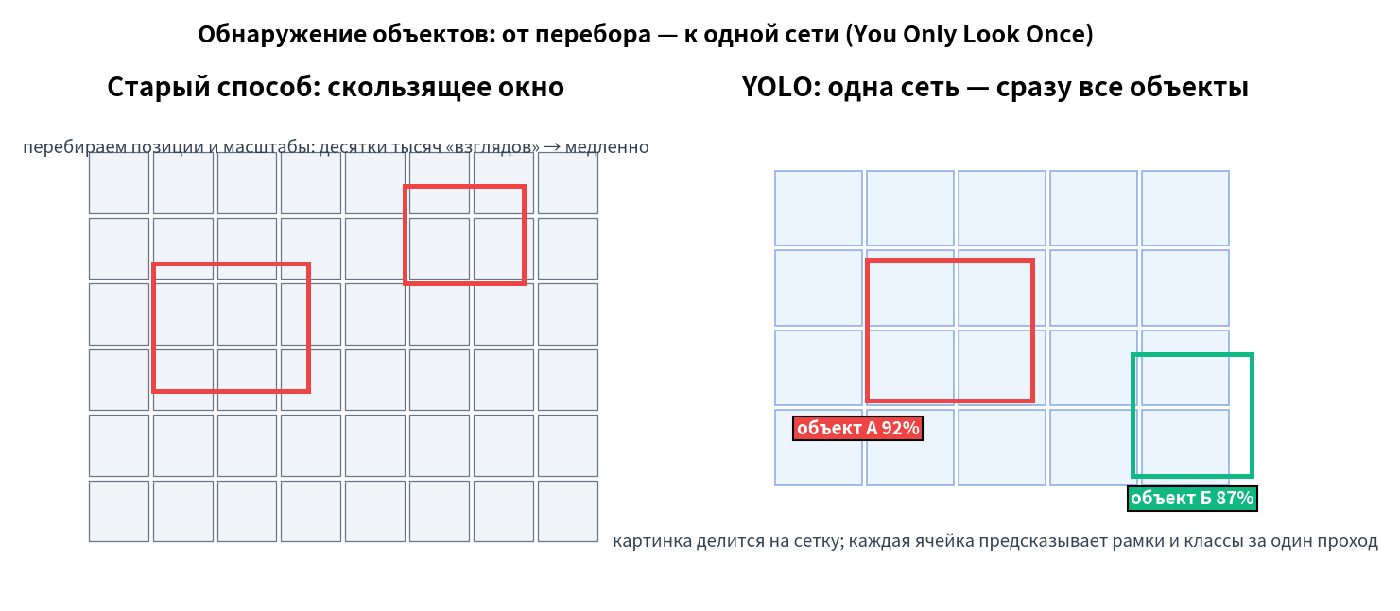

Классический перебор (2010-е): прогнать классификатор по десяткам тысяч окон всех размеров — часы на кадр. **YOLO** (2016) — принцип «смотреть один раз»: картинка делится на сетку, каждая ячейка сразу предсказывает рамки и классы всех объектов. Одна сеть, один проход — десятки кадров в секунду. На современных версиях (YOLOv8+) обучают и детекцию дефектов, и лиц, и номеров машин.

### 3.2. Распознавание лиц — конвейер, а не «волшебство»



### 🕰️ До нейросетей: каскад Хаара (Виолы — Джонса, 2001)

Жемчужина классической эпохи, всё ещё встроенная в OpenCV. Наблюдение: у человеческого лица устойчивые **светлые и тёмные зоны** — область глаз темнее щёк, переносица светлее глазных впадин. Алгоритм скользит по изображению окошком разных размеров и дешёвыми прямоугольными признаками за миллисекунды отбрасывает «точно не лицо», оставляя немного кандидатов. Именно каскады Хаара десятилетиями работали в фотоаппаратах для автофокусировки на лицах. Для учебных задач он и сегодня отличный инструмент: на практике 7 найдём им лицо на фотографии и попробуем веб-камеру в реальном времени.


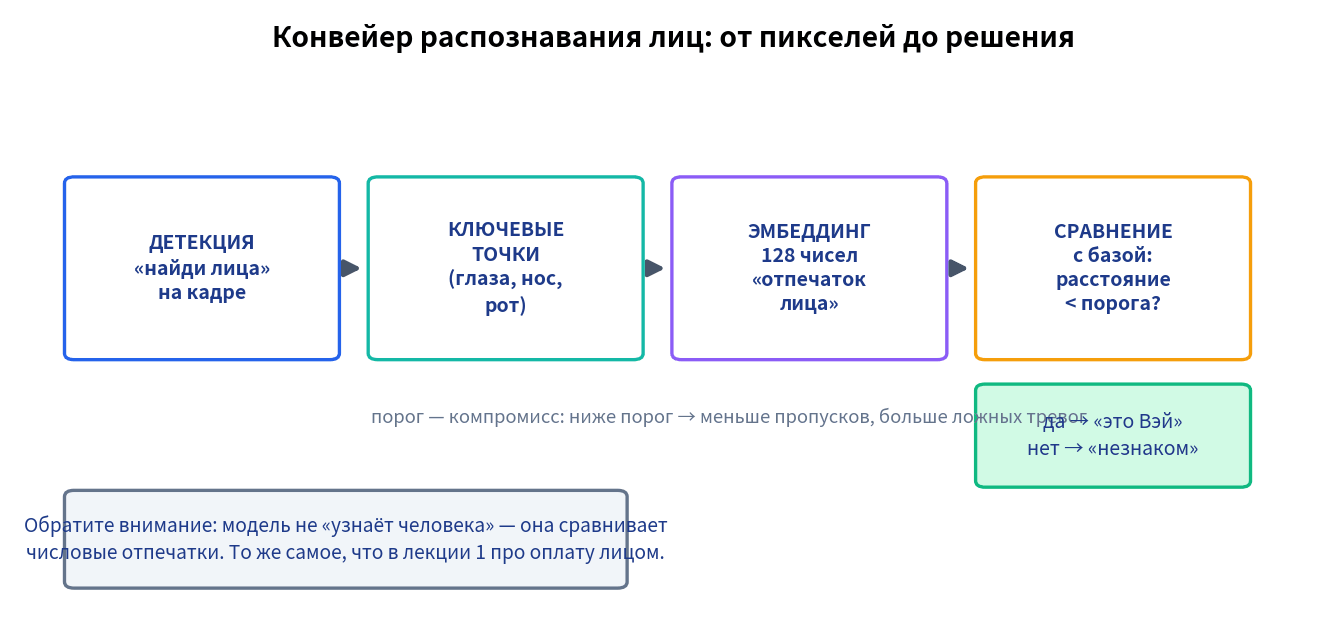

Обратите внимание на инженерное решение: распознавание = **детекция → выравнивание → эмбеддинг → сравнение с порогом**. Порог — настраиваемый компромисс безопасности (в лекции 4 это были precision/recall — та же качеля). Liveness-проверки (моргни, повернись) защищают от подмены фотографией.

> **Этическая заметка:** лицо — биометрия. В КНР и ЕС её обработка требует согласия и маркировки; подробности — в лекции 10. Для учёбы используйте открытые датасеты или своё лицо.


## 4. Интеллектуальная обработка речи (语音处理) (25–40 мин)

Речевые технологии делятся на два взаимно обратных направления:

### 🎤 ASR — Automatic Speech Recognition (自动语音识别)
**Речь → Текст.**  
Модель слушает аудио и превращает его в написанный текст.

**Как это работает:**
1. Аудио разбивается на короткие фрагменты (кадры).
2. Извлекаются акустические признаки (частоты, громкость).
3. Нейросеть сопоставляет эти признаки с фонемами и словами из словаря.

**Примеры в Китае:**
- 📱 **Голосовой ввод в WeChat (微信):** диктуете сообщение, оно мгновенно превращается в текст.
- 🏢 **iFlytek (科大讯飞):** лидер китайского рынка B2B-решений для ASR. Используется в умных колонках, медицинских диктофонах, судебных протоколах.
- 🎙️ **Субтитры в реальном времени** в DingTalk (钉钉) и Tencent Meeting.

### 🔊 TTS — Text-to-Speech (语音合成)
**Текст → Речь.**  
Модель превращает написанный текст в звучащий, естественный голос.

**Как это работает:**
Современные нейросетевые модели (например, на базе архитектур VITS или FastSpeech) генерируют речь, имитирующую интонации, ударения и паузы живого человека, а не робота.

**Примеры:**
- 🗣️ **Навигация Gaode (高德地图) / Baidu Maps:** голосом произносит «через 200 метров поверните направо».
- 🤖 **Голосовые помощники:** Xiao AI (小爱同学, Xiaomi), Xiaodu (小度, Baidu).
- 🎨 **Клонирование голоса:** современные TTS могут имитировать конкретный голос по 5-секундному образцу (требует осторожного использования из-за рисков дипфейков).

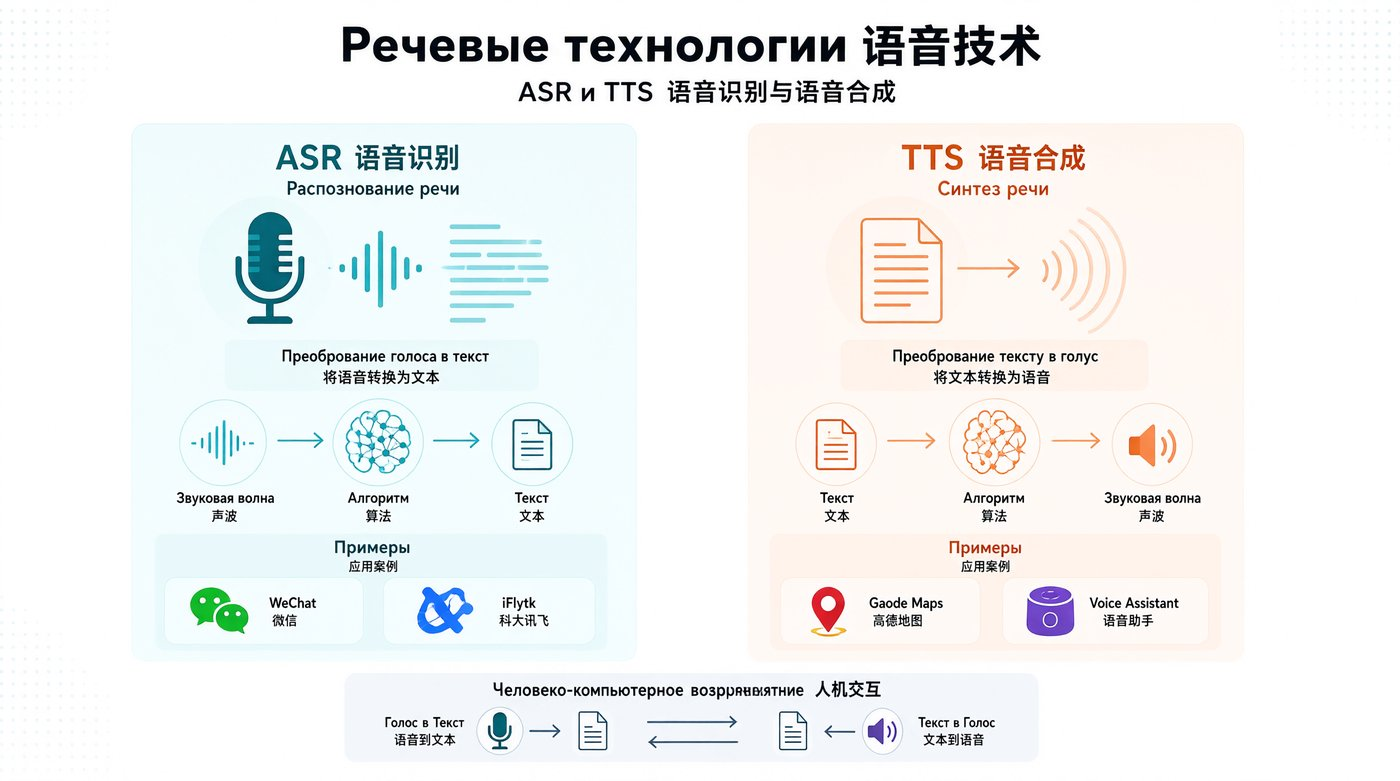
*Два направления: ASR (речь в текст) и TTS (текст в речь) с примерами китайских сервисов.*

> 💡 **Интересный факт:** В Китае распознавание речи (ASR) работает особенно хорошо для мандаринского диалекта. У него ограниченное число слогов (~400 с учётом тонов), что упрощает задачу для нейросети по сравнению с английским языком, где слов гораздо больше.

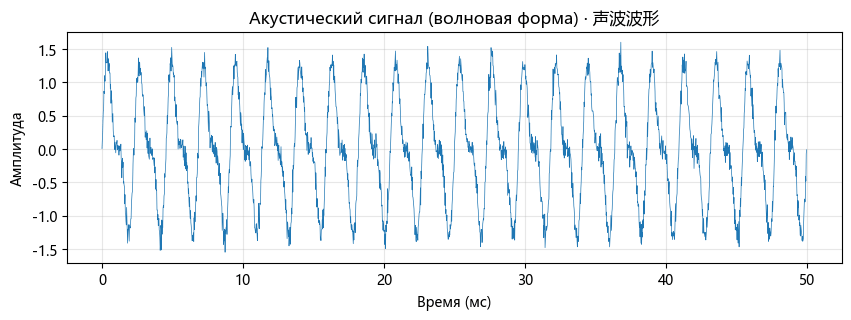

💡 Для компьютера эти 50 мс звука — это просто массив из 2205 чисел.
   ASR-модель анализирует такие массивы, находя в них паттерны, соответствующие словам.


In [ ]:
# Визуальная демонстрация: как выглядит "аудио" для компьютера
# Компьютер не "слышит" звук, он видит массив чисел (амплитуды волны)
import numpy as np
import matplotlib.pyplot as plt

# Создадим синтетический аудиосигнал (сумма двух синусоид + небольшой шум)
fs = 44100  # Частота дискретизации (как в CD-качестве)
t = np.linspace(0, 0.05, int(0.05 * fs), False) # 50 миллисекунд звука

# Сигнал: основная частота 440 Гц (нота Ля) + гармоника 880 Гц + шум
signal = np.sin(2 * np.pi * 440 * t) + 0.5 * np.sin(2 * np.pi * 880 * t) + 0.1 * np.random.randn(len(t))

plt.figure(figsize=(10, 3))
plt.plot(t * 1000, signal, linewidth=0.5) # время в миллисекундах
plt.title('Акустический сигнал (волновая форма) · 声波波形')
plt.xlabel('Время (мс)')
plt.ylabel('Амплитуда')
plt.grid(True, alpha=0.3)
plt.show()

print(f"💡 Для компьютера эти 50 мс звука — это просто массив из {len(signal)} чисел.")
print("   ASR-модель анализирует такие массивы, находя в них паттерны, соответствующие словам.")

## 4.1. Речь: звук, который можно увидеть

### Звук — тоже числа

Микрофон 44 100 раз в секунду измеряет давление воздуха. Две оси восприятия:


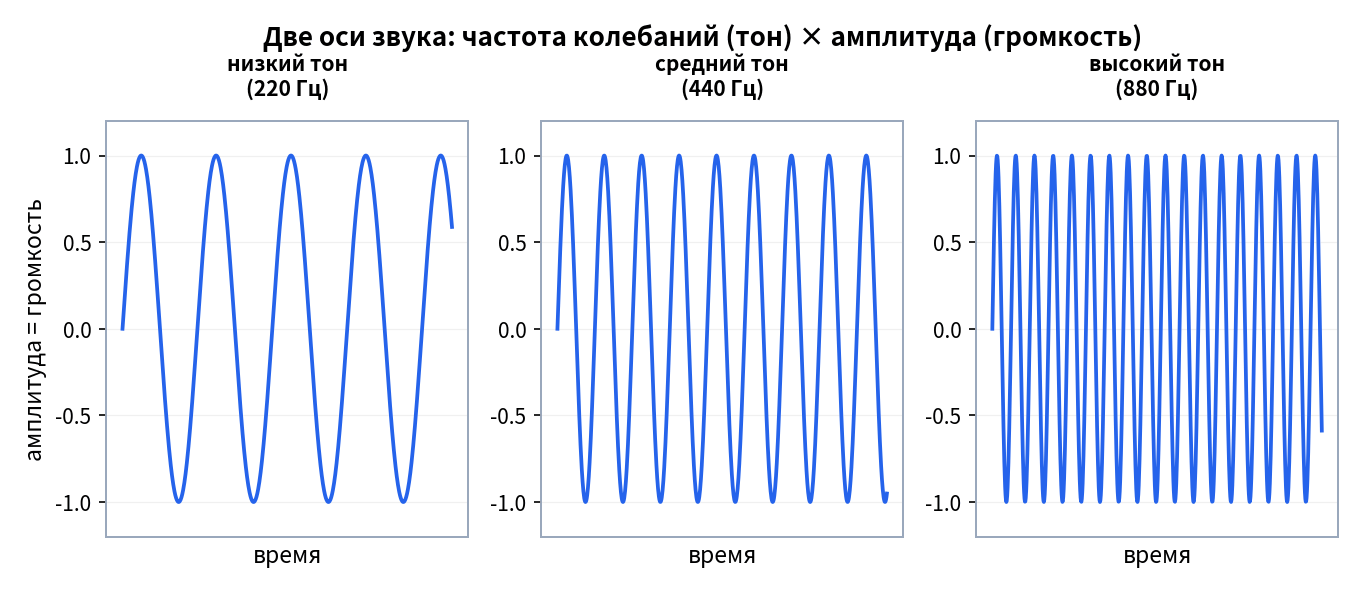

### 4.2. Спектрограмма: «фотография звука»

Хитрость, объединившая речь и зрение: режем волну на окошки по 20–30 мс и для каждого считаем, **какие частоты** в нём звучат. Получаем картинку «частота × время», где яркость = громкость:


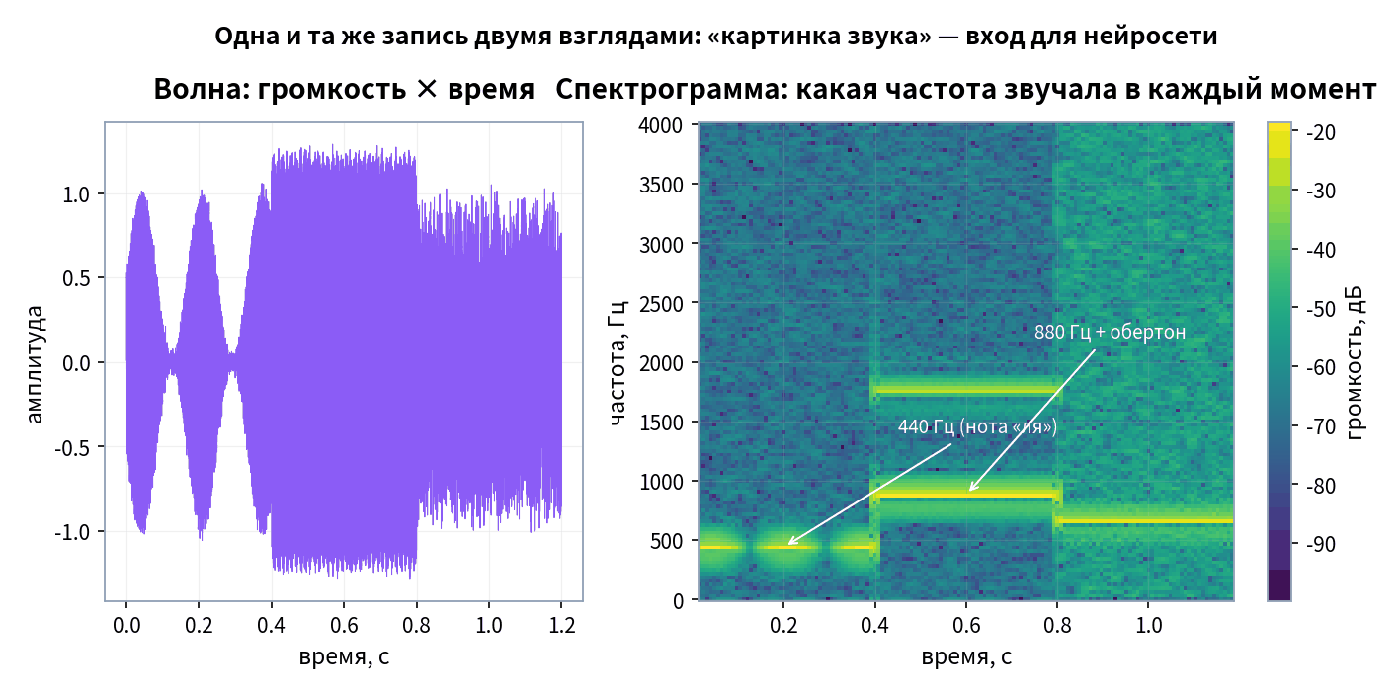

На спектрограмме видны «полосы» гласных (форманты) и «шум» согласных — фонетика превращается в геометрию. Дальше работает обычная CNN или аудио-трансформер. Полный конвейер:


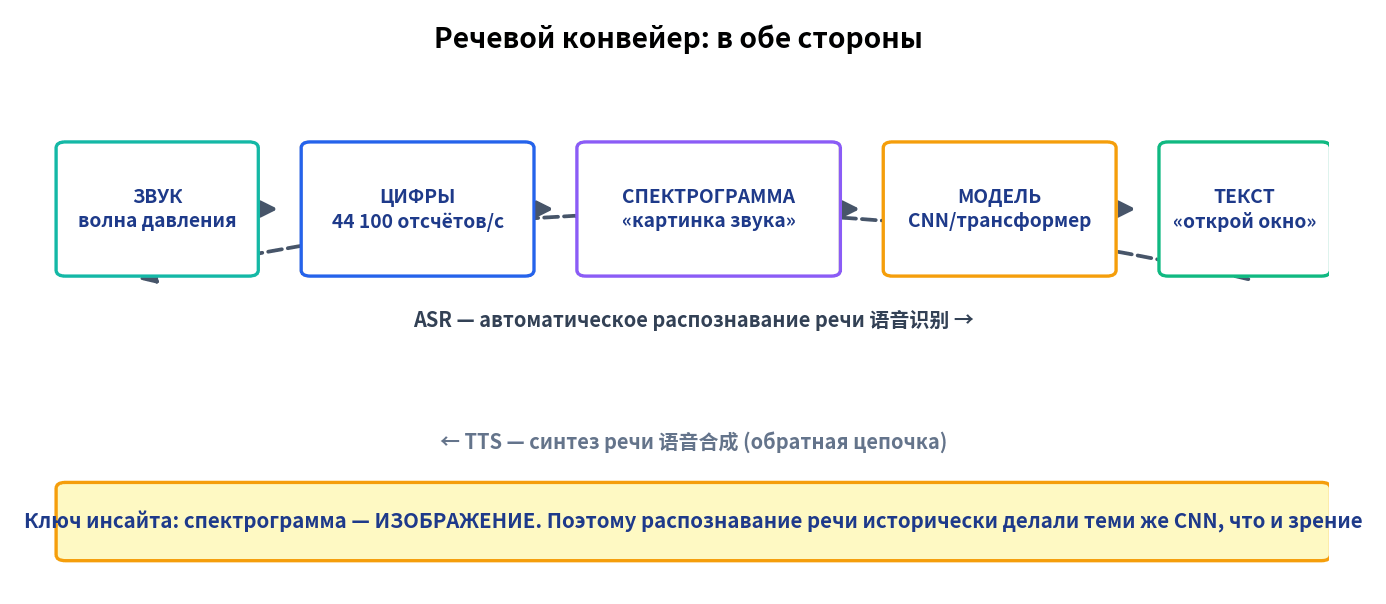

- **ASR** (автоматическое распознавание речи): whisper-класс моделей, китайские FunASR/Paraformer; готовый результат — субтитры, диктовка, голосовой ввод.
- **TTS** (синтез): текст → та же спектрограмма → волна; современные системы (CosyVoice и др.) клонируют голос по 10 секундам записи — с согласия владельца.
- **Голосовой помощник** = «горячее слово» + ASR + LLM (лекция 7) + TTS. Так работает Xiao AI (小爱同学) и колонка Xiaodu (小度).


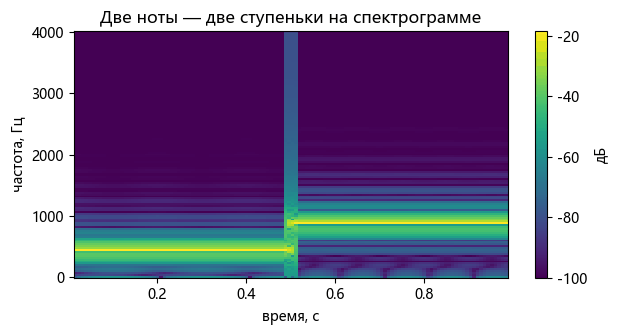

In [ ]:
# Спектрограмма своими руками (scipy есть в Anaconda)
from scipy import signal as sps

fs = 8000
t = np.linspace(0, 1, fs, False)
sound = np.concatenate([np.sin(2*np.pi*440*t[:4000]),          # «ля» 0.5 c
                        np.sin(2*np.pi*880*t[4000:])])          # «ля↑» 0.5 c
f, tt, Sxx = sps.spectrogram(sound, fs=fs, nperseg=256, noverlap=192)

plt.figure(figsize=(7, 3.2))
plt.pcolormesh(tt, f, 10*np.log10(Sxx + 1e-10), cmap='viridis', shading='auto')
plt.xlabel('время, с'); plt.ylabel('частота, Гц'); plt.title('Две ноты — две ступеньки на спектрограмме')
plt.colorbar(label='дБ'); plt.show()

## 5. Готовые блоки и живые применения

Собирать конвейеры из готовых моделей — норма индустрии:


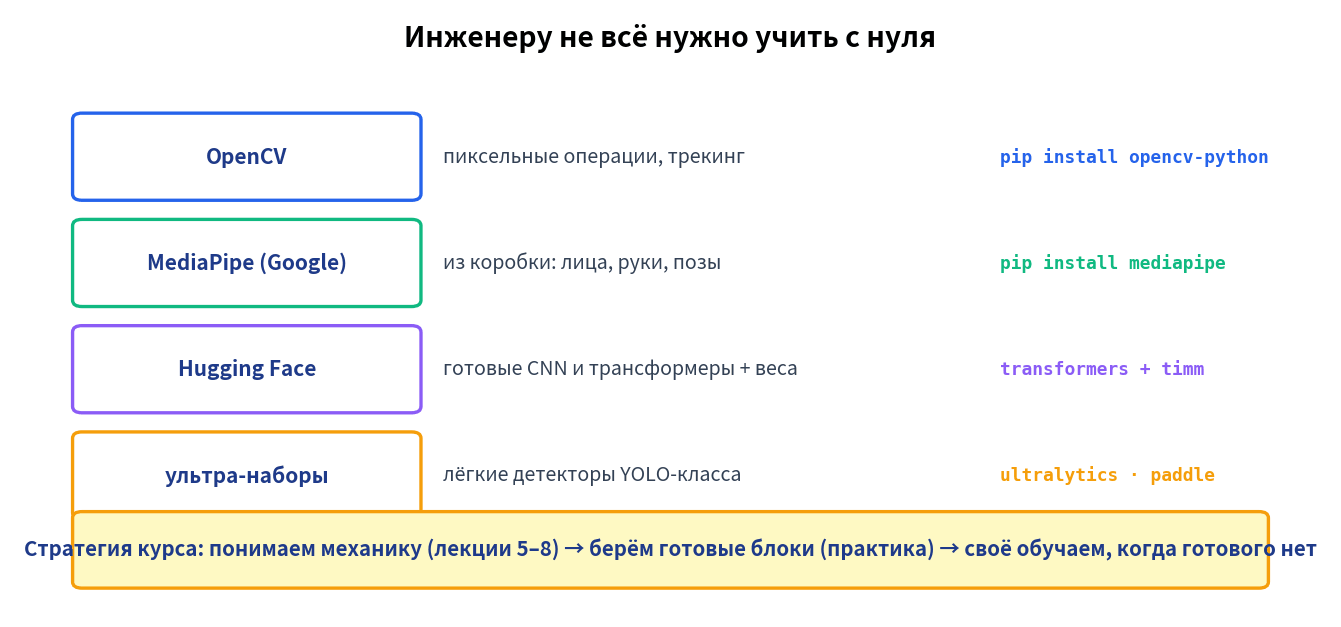


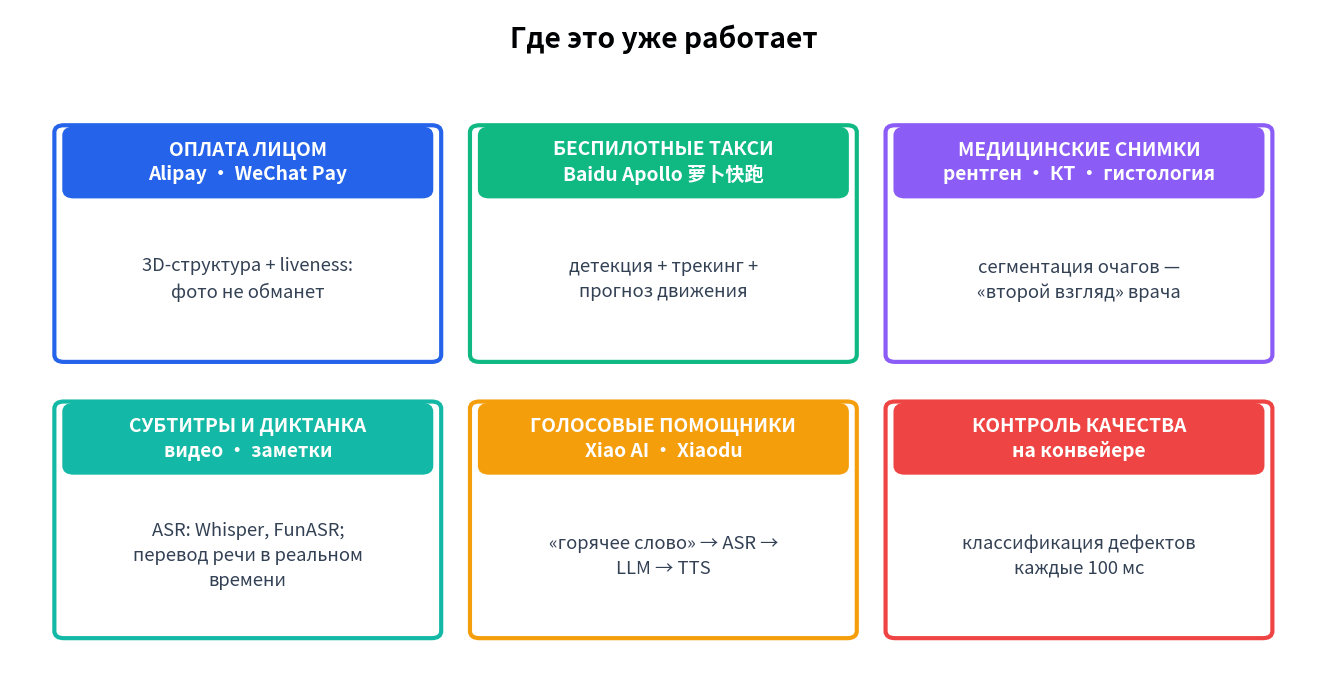

**❓ Обсудите:** для каждой карточки назовите, какая из трёх задач зрения (или речевой конвейер) там главная. Где критична задержка ответа? Где цена ошибки?



## 6. Генеративный ИИ: от GAN к диффузии

До 2014 года машины только **распознавали** — а потом научились **создавать**.

**GAN (генеративно-состязательная сеть, 生成对抗网络)** — дуэт из двух сетей: **генератор** рисует картинку, **дискриминатор** ловит подделку. Они соревнуются — как художник-фальсификатор и эксперт-искусствовед — и оба становятся сильнее: художник учится рисовать убедительнее, эксперт — замечать тоньше.

**Диффузионные модели** — сегодняшний главный подход. Сеть учится **убирать шум** с картинки, а генерация — путь от чистого шума к изображению через сотни маленьких «очисток» — как проявка фотографии. На этом принципе работают **Midjourney, Stable Diffusion и DALL·E**.

Применения давно вышли за рамки развлечений: концепты одежды для дизайнеров, молекулы-кандидаты для лекарств, варианты микросхем, обучающие примеры для других моделей. Обратная сторона — **дипфейки**: поддельные фото, аудио и видео, угроза доверию (подробно — в лекции 10). Умение отличать сгенерированный контент и маркировать его — уже базовая цифровая грамотность.

> 🎤 **Дополнение про речь:** направление **voice ID (проверка говорящего)** использует голос как пароль — так работают голосовые входы в банковских приложениях. Математика знакомая: голос превращается в вектор-эмбеддинг и сравнивается с образцом, как лицо в разделе 3.2.


---
## 🎬 Все видеоматериалы лекции 8
### 🇷🇺 РУС · русскоязычные видео (4)

| № | Видео | Источник | Длит. | Раздел лекции | Доступность |
|---|-------|----------|-------|----------------|-------------|
| 1 | [3.1 Особенности работы с аудиоданными \| Прикладные нейросети \| НИУ ВШЭ](https://vkvideo.ru/video-54799175_456241038) | VK · ВШЭ | 11:59 | Л8 §4: речь — звук как числа · | X |
| 2 | [3.4 Задача автоматического распознавания речи \| Прикладные нейросети \| НИУ ВШЭ](https://vkvideo.ru/video-54799175_456241041) | VK · ВШЭ | 5:59 | Л8 §4: ASR — распознавание речи ·[добавлено] | X |
| 3 | [Лекция. Задачи компьютерного зрения](https://vkvideo.ru/video-155161349_456239216) | VK · DLS-1 | 18:47 | Л8 §1.1: классификация, обнаружение, сегментация ·[добавлено] | X |
| 4 | [Лекция. Нейронная детекция объектов. Основы.](https://vkvideo.ru/video-155161349_456239245) | VK · DLS-1 | 25:37 | Л8 §3: обнаружение объектов — от скользящего окна к YOLO ·[добавлено] | X |


### 🇨🇳 中文 · китайскоязычные видео (32)
| № | Видео | Источник | Длит. | Раздел лекции | Доступность |
|---|-------|----------|-------|----------------|-------------|
| 1 | [Введение в машинное зрение](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=69)<br>· ориг.: *01 机器视觉介绍* | Bilibili · 清华AI | 8 мин | Л8 §1: три задачи зрения | ✓ |
| 2 | [Знакомство с OpenCV](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=70)<br>· ориг.: *02 OpenCV介绍* | Bilibili · 清华AI | 7 мин | Л8 §2: что умеет библиотека | ✓ |
| 3 | [OpenCV Python 图像处理 30分钟入门课程](https://www.bilibili.com/video/BV1BT4y1Z7WS) | Bilibili · OpenCV 30 мин | 25 мин | Л8 §2: обзор обработки изображений за 30 минут · [добавлено] | ✓ |
| 4 | [Цветовые пространства RGB и BGR](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=79)<br>· ориг.: *06 RGB和BGR颜色空间* | Bilibili · 清华AI | 5 мин | Л8 §2: цвет в OpenCV | ✓ |
| 5 | [Цветовые модели HSV, HSL и YUV](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=80)<br>· ориг.: *01 HSV和HSL和YUV* | Bilibili · 清华AI | 34:39 | Л8 §2: цветовые модели · [добавлено] | ✓ |
| 6 | [Арифметика изображений: сложение и др.](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=90)<br>· ориг.: *01 图像运算之加减乘除* | Bilibili · 清华AI | 24:18 | Л8 §2: яркость и контраст · [добавлено] | ✓ |
| 7 | [Операция свёртки над изображением](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=99)<br>· ориг.: *01 卷积操作* | Bilibili · 清华AI | 38 мин | Л8 §2 / Л6 §4: свёртка на картинках | ✓ |
| 8 | [Усредняющий и box-фильтры](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=100)<br>· ориг.: *02 均值滤波和方盒滤波* | Bilibili · 清华AI | 10 мин | Л8 §2: подавление шума | ✓ |
| 9 | [Гауссово размытие](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=101)<br>· ориг.: *03 高斯滤波* | Bilibili · 清华AI | 39 мин | Л8 §2: сглаживание изображений | ✓ |
| 10 | [Медианный фильтр](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=102)<br>· ориг.: *01 中值滤波* | Bilibili · 清华AI | 13 мин | Л8 §2: шум «соль и перец» | ✓ |
| 11 | [Билатеральный фильтр](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=103)<br>· ориг.: *02 双边滤波* | Bilibili · 清华AI | 19:05 | Л8 §2: сглаживание с сохранением границ · [добавлено] | ✓ |
| 12 | [Оператор Собеля (градиенты изображения)](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=104)<br>· ориг.: *04 sobel算子* | Bilibili · 清华AI | 40 мин | Л8 §2: выделение границ | ✓ |
| 13 | [Оператор Щарра](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=105)<br>· ориг.: *04 scharr算子* | Bilibili · 清华AI | 6:28 | Л8 §2: градиенты · [добавлено] | ✓ |
| 14 | [Оператор Лапласа](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=106)<br>· ориг.: *05 拉普拉斯算子* | Bilibili · 清华AI | 15:06 | Л8 §2: градиенты · [добавлено] | ✓ |
| 15 | [Детектор границ Кэнни (Canny)](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=107)<br>· ориг.: *01 Canny边缘检测* | Bilibili · 清华AI | 28 мин | Л8 §2: детектор границ | ✓ |
| 16 | [Разбор алгоритма Canny (детектор границ)](https://www.bilibili.com/video/BV1VVqhBvEy5)<br>· ориг.: *Canny算法讲解* | Bilibili · BrAyDNe | 10:05 | Л8 §2: Canny — фильтр, градиент, NMS, двойной порог · [добавлено] | ✓ |
| 17 | [Глобальная бинаризация](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=108)<br>· ориг.: *02 全局二值化* | Bilibili · 清华AI | 19 мин | Л8 §2: пороговая обработка | ✓ |
| 18 | [Адаптивная пороговая бинаризация](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=109)<br>· ориг.: *03 自适应阈值二值化* | Bilibili · 清华AI | 19:38 | Л8 §2: пороговая обработка · [добавлено] | ✓ |
| 19 | [Операция эрозии](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=110)<br>· ориг.: *04 腐蚀操作* | Bilibili · 清华AI | 9:52 | Л8 §2: морфология · [добавлено] | ✓ |
| 20 | [Получение морфологического ядра](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=111)<br>· ориг.: *05 获取形态学卷积核* | Bilibili · 清华AI | 7:37 | Л8 §2: морфология · [добавлено] | ✓ |
| 21 | [Операция дилатации](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=112)<br>· ориг.: *06 膨胀操作* | Bilibili · 清华AI | 6:25 | Л8 §2: морфология · [добавлено] | ✓ |
| 22 | [Морфологическая операция «открытие»](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=113)<br>· ориг.: *01 开运算* | Bilibili · 清华AI | 12 мин | Л8 §2: морфология | ✓ |
| 23 | [Морфологическая операция «закрытие»](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=114)<br>· ориг.: *02 闭运算* | Bilibili · 清华AI | 5 мин | Л8 §2: морфология | ✓ |
| 24 | [Морфологический градиент](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=115)<br>· ориг.: *03 形态学梯度* | Bilibili · 清华AI | 4:48 | Л8 §2: морфология · [добавлено] | ✓ |
| 25 | [Операция Top Hat](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=116)<br>· ориг.: *04 顶帽操作* | Bilibili · 清华AI | 3:51 | Л8 §2: морфология · [добавлено] | ✓ |
| 26 | [Операция Black Hat](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=117)<br>· ориг.: *05 黑帽操作* | Bilibili · 清华AI | 2:42 | Л8 §2: морфология · [добавлено] | ✓ |
| 27 | [Обнаружение глаз](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=167)<br>· ориг.: *02 人眼检测* | Bilibili · 清华AI | 13:57 | Л8 §3.2: конвейер лиц · [добавлено] | ✓ |
| 28 | [Обнаружение лиц](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=169)<br>· ориг.: *01 人脸检测* | Bilibili · 清华AI | 40 мин | Л8 §3.2: каскады Хаара и детекция лиц | ✓ |
| 29 | [Обнаружение объектов](https://www.bilibili.com/video/BV1EY6FBwE8P?p=122)<br>· ориг.: *122.1-物体检测* | Bilibili · 李沐 | 11 мин | Л8 §3: рамки объектов, детекция | ✓ |
| 30 | [Обнаружение объектов (обзор)](https://www.bilibili.com/video/BV1EY6FBwE8P?p=130)<br>· ориг.: *130.1-目标检测-* | Bilibili · 李沐 | 42 мин | Л8 §3: от окон к детекторам | ✓ |
| 31 | [Семантическая сегментация](https://www.bilibili.com/video/BV1EY6FBwE8P?p=135)<br>· ориг.: *135.1-语义分割-* | Bilibili · 李沐 | 7 мин | Л8 §1.1: сегментация | ✓ |
| 32 | [Обработка речевого сигнала и признаков (в т.ч. спектрограммы)](https://www.bilibili.com/video/BV13h7wzQE5E?p=2)<br>· ориг.: *语音信号处理以及特征处理* | Bilibili · курс ASR | эп. курса (12 эп.) | Л8 §4.2: спектрограмма — «фотография звука» ·  | ✓ |



---
## ❓ Мини-тест и закрепление (20 мин)

Проверьте себя, нажав на вопрос, чтобы увидеть ответ.

**1. Чем классификация изображения отличается от обнаружения объектов?**
<details>
<summary>Показать ответ</summary>
<b>Классификация</b> даёт один общий ярлык для всей картинки (например, «это машина»). <b>Обнаружение объектов</b> находит несколько предметов и рисует вокруг них рамки с координатами, показывая, где именно они находятся. Классификация отвечает на вопрос «Что?», обнаружение — на вопрос «Где и что?».
</details>

**2. Для чего нужно размытие (blur) в OpenCV перед поиском границ?**
<details>
<summary>Показать ответ</summary>
Чтобы убрать мелкий цифровой шум. Если этого не сделать, алгоритм (например, Canny) примет шум за ложные границы, и результат будет загрязнён лишними линиями. Размытие сглаживает изображение, оставляя только настоящие контуры объектов.
</details>

**3. Что такое ASR и TTS?**
<details>
<summary>Показать ответ</summary>
<b>ASR (语音识别)</b> — распознавание речи (перевод голоса в текст). Пример: голосовой ввод в WeChat.<br><br>
<b>TTS (语音合成)</b> — синтез речи (перевод текста в голос). Пример: голосовые подсказки навигатора Gaode.
</details>

**4. Назовите три применения компьютерного зрения в повседневной жизни.**
<details>
<summary>Показать ответ</summary>
1. Разблокировка телефона по лицу (распознавание лиц).<br>
2. Фильтрация фото в галерее (классификация: кошки, собаки, еда).<br>
3. Автономные автомобили (обнаружение объектов: пешеходы, машины, знаки).
</details>

**5. Почему YOLO называется «You Only Look Once»?**
<details>
<summary>Показать ответ</summary>
Потому что алгоритм обрабатывает изображение за один проход (один «взгляд»), в отличие от старых методов, которые сканировали картинку много раз. Это делает YOLO очень быстрым и подходящим для работы в реальном времени.
</details>

### Контрольные вопросы

Нажмите на вопрос, чтобы раскрыть образец ответа.

**1. Чем сегментация принципиально отличается от детекции по формату выхода модели?**
<details>
<summary>Показать ответ</summary>
Детекция выдаёт <b>рамки (bounding boxes)</b> вокруг объектов + классы + уверенность. Сегментация выдаёт <b>маску для каждого пикселя</b> — «какой пиксель кому принадлежит». Это разные форматы ответа: прямоугольник против точной раскраски контура.
</details>

**2. Почему правило «найти все красные предметы» лучше писать в HSV, а не в RGB?**
<details>
<summary>Показать ответ</summary>
<b>HSV</b> разделяет оттенок (Hue), насыщенность и яркость: красный предмет остаётся «красным по оттенку» и в тени, и при ярком свете. В RGB «краснота» — просто большие значения R, которые скачут при любом изменении освещения, и правило начинает ловить и терять предметы.
</details>

**3. Умный дом должен включать свет, когда в комнату входит человек. Какая задача зрения достаточна? Нужна ли идентификация личности?**
<details>
<summary>Показать ответ</summary>
Достаточно <b>детекции</b>: «есть человек в комнате» → включить свет. Идентификация личности избыточна для этой задачи и этически напряжённа: лицо — биометрия, её сбор требует согласия и законных оснований. Хорошее правило инженера: решать задачу самой дешёвой задачей зрения.
</details>

**4. Что увидит модель на спектрограмме слова «мама»? Почему там две «ступеньки»?**
<details>
<summary>Показать ответ</summary>
Слово «мама» — два одинаковых слога «ма», и на спектрограмме картина <b>повторяется дважды</b>: две «ступеньки» из полосы согласной «м» и форманты гласной «а». Одинаковые звуки — одинаковые узоры; фонетика превращается в геометрию, которую уже распознаёт обычная CNN.
</details>

**5. Почему ASR-модели исторически выросли из компьютерного зрения?**
<details>
<summary>Показать ответ</summary>
Звук превращают в <b>спектрограмму — «фотографию звука»</b> (частота × время, яркость = громкость). Дальше работает тот же CNN, что и для картинок: научившись распознавать изображения, модель автоматически умеет «смотреть» на звук.
</details>

**6. Голосовой помощник Xiao AI — перечислите его четыре звена по конвейеру.**
<details>
<summary>Показать ответ</summary>
<b>1.</b> «Горячее слово» — пробуждение; <b>2. ASR</b> — речь → текст; <b>3. LLM</b> — понимание вопроса и формулировка ответа; <b>4. TTS</b> — озвучивание ответа. Одна бытовая фраза — четыре ИИ-системы.
</details>

**7. Какие две аугментации из лекции 6 опасны для детекции номеров машин?**
<details>
<summary>Показать ответ</summary>
<b>Сильный поворот</b> и <b>отражение</b>: цифры и буквы меняют смысл и ориентацию (6↔9, зеркальный номер нечитаем) — модель учится на неправильных метках. Безопасны лёгкие сдвиги, шум, яркость.
</details>

**8. Ваш детектор брака в лаборатории даёт 99%, на конвейере — 82%. Назовите три вероятные причины и что делать.**
<details>
<summary>Показать ответ</summary>
Причины (любые три): <b>1.</b> другое освещение, фон и угол камеры; <b>2.</b> шум, вибрация, сжатие видео; <b>3.</b> распределение деталей сместилось (дрейф) — лабораторная выборка не покрывала реальные вариации. Что делать: собрать кадры прямо с конвейера, добавить аугментацию под реальные условия, переобучить и откалибровать пороги.
</details>

**9. На каком наблюдении о лицах построен каскад Хаара? Почему алгоритм такой быстрый?**
<details>
<summary>Показать ответ</summary>
У человеческого лица устойчивые <b>светлые и тёмные зоны</b>: область глаз темнее щёк, переносица светлее глазных впадин. Быстрый, потому что дешёвые прямоугольные признаки за миллисекунды <b>отбрасывают «точно не лицо»</b>, и тяжёлая проверка остаётся только для горстки кандидатов — каскад отказов.
</details>

**10. Объясните метафору «художник и искусствовед» для GAN. Почему обе сети со временем улучшаются?**
<details>
<summary>Показать ответ</summary>
<b>Генератор</b> — художник-фальсификатор: рисует картинки; <b>дискриминатор</b> — эксперт-искусствовед: ловит подделки. Они соревнуются, и это заставляет обоих расти: художник учится рисовать убедительнее (обмануть эксперта), эксперт — замечать подделку тоньше (не быть обманутым).
</details>

**11. Как диффузионная модель порождает изображение? Какие популярные сервисы на ней основаны?**
<details>
<summary>Показать ответ</summary>
Сеть учится <b>убирать шум</b> с картинки; генерация — путь от чистого шума к изображению через сотни маленьких «очисток» — как проявка фотографии. На этом принципе работают <b>Midjourney, Stable Diffusion и DALL·E</b>.
</details>

**12. Опишите конвейер распознавания лиц от пикселей до имени. На какой знакомой идее построен шаг «эмбеддинг»?**
<details>
<summary>Показать ответ</summary>
<b>Детекция лица → выравнивание → эмбеддинг → сравнение с порогом</b>: лицо превращается в вектор из ~128 чисел и сравнивается с сохранённым образцом. Эмбеддинг — та же идея «смысл → геометрия», что у слов (лекция 7) и рекомендаций (лекция 2): <b>близко = похоже</b>.
</details>

**13. Что такое voice ID и где это направление применяется?**
<details>
<summary>Показать ответ</summary>
<b>Voice ID (проверка говорящего)</b> — голос как пароль: голос превращается в вектор-эмбеддинг и сравнивается с образцом, как лицо в разделе 3.2. Применение: голосовой вход в банковских приложениях и подтверждение личности по телефону.
</details>


## 📚 Глоссарий Лекции 8 (词汇表)

Термины компьютерного зрения и речи (термины LLM — в Лекции 7).

| Термин (рус) | English | 中文 | Пояснение |
|--------------|---------|------|-----------|
| Компьютерное зрение | Computer Vision | 计算机视觉 | Дисциплина обучения компьютеров «видеть»: распознавать объекты на изображениях. |
| Классификация изображений | Image classification | 图像分类 | Один объект на картинке → одна метка класса. |
| Детекция объектов | Object detection | 目标检测 | Несколько объектов + рамки (bounding boxes) на одном кадре. |
| Сегментация | Segmentation | 分割 | Попиксельная разметка: каждому пикселю — класс. |
| OpenCV | OpenCV | 开源视觉库 | Библиотека компьютерного зрения; 2500+ функций, C++ + Python. |
| BGR / RGB | BGR / RGB color order | 通道顺序 | OpenCV использует BGR, matplotlib — RGB; путать нельзя. |
| HSV | HSV color space | HSV色彩空间 | Hue, Saturation, Value; устойчива к теням, удобнее для сегментации. |
| Фильтр | Filter | 滤波 | Операция над пикселями: размытие, резкость, шумоподавление. |
| Пороговая обработка | Thresholding | 阈值处理 | Бинаризация: пиксели > T → белые, иначе чёрные. |
| Детектор Canny | Canny edge detector | Canny边缘检测 | Многоступенчатый алгоритм выделения контуров (1986). |
| Каскад Хаара | Haar cascade | 哈尔级联 | Классический детектор лиц Виолы–Джонса (2001). |
| YOLO | YOLO (You Only Look Once) | YOLO | Современный детектор «один проход» по сетке ячеек. |
| MediaPipe | MediaPipe | MediaPipe | Библиотека Google для зрения/жестов на мобильных устройствах. |
| Спектрограмма | Spectrogram | 频谱图 | Визуальное представление звука: время × частота × амплитуда. |
| ASR | Automatic Speech Recognition | 语音识别 | Преобразование аудио в текст; Whisper и др. |
| TTS | Text-to-Speech | 语音合成 | Генерация речи из текста; навигаторы, ассистенты, озвучка. |
| Форманты | Formants | 共振峰 | Пики в спектре речи; определяют гласные звуки. |
| Hugging Face | Hugging Face | 模型仓库 | Платформа моделей и датасетов; «GitHub для ML». |


## 🎓 Итоги Лекции 8

Лекция показала три задачи зрения (классификация, детекция, сегментация), базовые операции OpenCV, современных детекторов и распознавания лиц, а также речевой конвейер: волна → спектрограмма → модель → текст (и обратно, TTS). Готовые инструменты: OpenCV, MediaPipe, Hugging Face.

### 🔑 Главные выводы

1. Три задачи зрения: классификация (метка), детекция (рамки), сегментация (маски). Сложность и требования к данным растут в этом же порядке.
2. Зрение сложно из-за вариаций: свет, ракурс, сдвиги, окклюзия → данные и аугментация решают.
3. OpenCV — пиксельная гигиена: яркость/контраст/порог/размытие/Canny; HSV устойчивее RGB к теням.
4. Детекция: от скользящего окна к YOLO «один проход». Лица: детекция → эмбеддинг → порог; лицо — биометрия, нужны согласие и осторожность.
5. Речь = числа: волна → спектрограмма («картинка звука») → CNN/трансформер → текст; TTS — обратная цепочка.
6. Готовые блоки (OpenCV, MediaPipe, Hugging Face) покрывают 80% промышленных сценариев — учите механику, но не изобретайте велосипед.

### 📝 Домашнее задание

1. **Пороговая инспекция.** Сделайте 5 «деталей» градаций серого (np-массивы). Подберите порог так, чтобы модель «забраковала» ровно две самые тёмные. Проверьте устойчивость порога к яркости +30.
2. **Спектрограммы-отпечатки.** Синтезируйте сигналы: одна нота, аккорд, «щелчок». Постройте три спектрограммы и опишите различия в 5 предложениях (что видит модель?).
3. **Разбор кейса.** Выберите любую систему из рисунка «Где это уже работает» и распишите её конвейер по блокам лекции (какие модели, какой вход-выход, где пороги). Полстраницы.

### 📅 Следующее занятие

**Лекция 9: Внедрение ИИ-сервисов: от ноутбука до продакшена**

**Практика 9: Веб-сервис на Flask для распознавания цифр**

---

<center><i>Преподаватель: _______________</i></center>
<center><i>Дата проведения: _______________</i></center>